# Electricity Consumption Dataset — Part 1

## Introduction

This notebook was created for the IT Department of Albstadt-Sigmaringen 
University. The goal is to generate a simulated electricity consumption 
dataset for the entire university campus, covering all electricity used 
for powering devices, lighting, heating water, and other equipment.

Since no historical consumption data currently exists, we agreed as a team 
to start with a simulation — generating a dataset that reflects how 
electricity consumption at a university would realistically behave 
throughout the year.

The dataset covers every hour of 2024, resulting in 8,784 individual 
measurements. Our simulation is driven by two key assumptions: that 
consumption varies depending on the time of day, and that weekdays have 
significantly higher activity than weekends.

## Mandatory Columns

| Column Name | Description |
|------------|-------------|
| timestamp | Every hour from 2024-01-01 00:00 to 2024-12-31 23:00 |
| consumption_kwh | Electricity consumption for that hour in kWh |

---

## Dataset Requirements

| Requirement | Value |
|------------|--------|
| Year Covered | 2024 |
| Measurement Frequency | Hourly |
| Number of Days | 366 (Leap Year) |
| Hours per Day | 24 |
| Total Rows | 8784 |
| CSV File Name | consumption.csv |
| Notebook File Name | part1.ipynb |

---

## Expected Dataset Structure

| timestamp | hours | consumption_kwh | day_name | holiday | semester_status |
|------------|-------|----------------|----------|----------|----------------|
| 2024-01-01 00:00:00 | 0 | 247.5 | Monday | True | Break |
| 2024-01-01 01:00:00 | 1 | 259.0 | Monday | True | Break |
| 2024-01-01 02:00:00 | 2 | 254.6 | Monday | True | Break |
| ... | ... | ... | ... | ... | ... |
| 2024-12-31 23:00:00 | 23 | 265.4 | Tuesday | False | Semester |

---

## Electricity Consumption Assumptions

### Time-Based Consumption

| Time Period | Consumption Level |
|------------|------------------|
| Morning (06:00–11:59) | Medium |
| Afternoon (12:00–17:59) | High |
| Evening (18:00–21:59) | Medium |
| Night (22:00–05:59) | Low |

### Day-Based Consumption

| Day Type | Consumption Level |
|----------|------------------|
| Weekday (Monday–Friday) | High |
| Weekend (Saturday–Sunday) | Low |


### Additional Assumptions

| Assumption | Description |
|------------|-------------|
| Base Load Exists | Servers, security systems, emergency lighting, and essential equipment consume electricity continuously |
| No Missing Data | Every hour in 2024 has a consumption measurement |
| Random Variation | Small random fluctuations are added to simulate real-world usage patterns |
| Positive Consumption | Electricity consumption values cannot be negative |
| Peak Activity Hours | Highest consumption occurs during normal university operating hours |
| Reduced Weekend Usage | Campus occupancy and electricity demand decrease on weekends |

---


## Generating Hourly Timestamps

The dataset requires one electricity consumption measurement for every hour of the year 2024.

Since 2024 is a leap year, the dataset must cover:

- Start Date: 2024-01-01 00:00:00
- End Date: 2024-12-31 23:00:00
- Frequency: Hourly

To generate these timestamps, NumPy's `arange()` function is used together with Python's `datetime` and `timedelta` objects. The resulting array is converted into datetime values and later used as the foundation of the dataset.

In [128]:
pip install pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


## Setup

We use three libraries:
- **pandas** for building and manipulating the DataFrame
- **numpy** for generating the timestamp array
- **matplotlib** for visualization

In [129]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Generate Hourly Timestamps

We create one timestamp per hour for the entire year 2024 using `np.arange()` with a `timedelta` step of 1 hour. The range starts at `2024-01-01 00:00` and ends at `2024-12-31 23:00`, producing exactly 8,784 timestamps.

In [130]:
from datetime import datetime, timedelta

timestamps = np.arange(
    datetime(2024, 1, 1),
    datetime(2025, 1, 1),
    timedelta(hours=1)
).astype(datetime)

timestamps

array([datetime.datetime(2024, 1, 1, 0, 0),
       datetime.datetime(2024, 1, 1, 1, 0),
       datetime.datetime(2024, 1, 1, 2, 0), ...,
       datetime.datetime(2024, 12, 31, 21, 0),
       datetime.datetime(2024, 12, 31, 22, 0),
       datetime.datetime(2024, 12, 31, 23, 0)],
      shape=(8784,), dtype=object)

## Build the Base DataFrame

The timestamp array is loaded into a pandas DataFrame with a single column `timestamp`. This serves as the foundation to which all consumption values will be added.

In [131]:
df = pd.DataFrame(timestamps, columns=["timestamp"])
df

,timestamp
0,2024-01-01 00:00:00
1,2024-01-01 01:00:00
2,2024-01-01 02:00:00
3,2024-01-01 03:00:00
4,2024-01-01 04:00:00
...,...
8779,2024-12-31 19:00:00
8780,2024-12-31 20:00:00
8781,2024-12-31 21:00:00
8782,2024-12-31 22:00:00


## Time-Based Consumption Assumptions

| Period | Hours | Consumption Level | Consumption (kWh) |
|----------|----------|----------|----------|
| Morning | 06:00 - 11:59 | Medium | 450 |
| Afternoon | 12:00 - 17:59 | High | 650 |
| Evening | 18:00 - 21:59 | Medium | 450 |
| Night | 22:00 - 05:59 | Low | 250 |

## Extract Hour of the Day
To assign consumption values based on the defined time periods, the hour component is extracted from each timestamp.

The extracted hour serves as the key input for the consumption model and allows each observation to be categorized into one of the predefined operational periods.

In [132]:
hours = df["timestamp"].dt.hour
hours

0        0
1        1
2        2
3        3
4        4
        ..
8779    19
8780    20
8781    21
8782    22
8783    23
Name: timestamp, Length: 8784, dtype: int32

In [133]:
df["hours"]=hours
df

,timestamp,hours
0,2024-01-01 00:00:00,0
1,2024-01-01 01:00:00,1
2,2024-01-01 02:00:00,2
3,2024-01-01 03:00:00,3
4,2024-01-01 04:00:00,4
...,...,...
8779,2024-12-31 19:00:00,19
8780,2024-12-31 20:00:00,20
8781,2024-12-31 21:00:00,21
8782,2024-12-31 22:00:00,22


### Why these values?

A university campus has predictable activity patterns. We assume:
- **Night (250 kWh):** Minimal activity — only base loads such as servers, security systems, and emergency lighting remain active.
- **Morning & Evening (450 kWh):** Moderate activity — classes and offices are occupied but not at full capacity.
- **Afternoon (650 kWh):** Peak activity — lectures, labs, and administrative work are all running simultaneously.

The `get_consumption()` function maps each hour to its corresponding consumption level, which is then applied to every row in the dataset.

## Define Baseline Consumption Model

A baseline consumption model is created to simulate typical electricity usage throughout the day based on expected university activity levels. This model assigns different consumption values to morning, afternoon, evening, and night periods, establishing the foundation for all subsequent energy consumption calculations.

In [134]:
def get_consumption(hour):
    if 6 <= hour <= 11:      # Morning
        return 450
    elif 12 <= hour <= 17:   # Afternoon
        return 650
    elif 18 <= hour <= 21:   # Evening
        return 450
    else:                    # Night (22-23 and 0-5)
        return 250

df["consumption_kwh"] = df["hours"].apply(get_consumption)

df

,timestamp,hours,consumption_kwh
0,2024-01-01 00:00:00,0,250
1,2024-01-01 01:00:00,1,250
2,2024-01-01 02:00:00,2,250
3,2024-01-01 03:00:00,3,250
4,2024-01-01 04:00:00,4,250
...,...,...,...
8779,2024-12-31 19:00:00,19,450
8780,2024-12-31 20:00:00,20,450
8781,2024-12-31 21:00:00,21,450
8782,2024-12-31 22:00:00,22,250


## Apply Weekend Reduction

University campuses have significantly lower activity on weekends — fewer students, no scheduled lectures, and reduced administrative operations. We extract the day name from each timestamp to identify Saturdays and Sundays.

In [135]:
df["day_name"] = df["timestamp"].dt.day_name()
df["day_name"]

0        Monday
1        Monday
2        Monday
3        Monday
4        Monday
         ...   
8779    Tuesday
8780    Tuesday
8781    Tuesday
8782    Tuesday
8783    Tuesday
Name: day_name, Length: 8784, dtype: str

In [136]:
hours = df["timestamp"].dt.hour
df["hours"] = hours

df

,timestamp,hours,consumption_kwh,day_name
0,2024-01-01 00:00:00,0,250,Monday
1,2024-01-01 01:00:00,1,250,Monday
2,2024-01-01 02:00:00,2,250,Monday
3,2024-01-01 03:00:00,3,250,Monday
4,2024-01-01 04:00:00,4,250,Monday
...,...,...,...,...
8779,2024-12-31 19:00:00,19,450,Tuesday
8780,2024-12-31 20:00:00,20,450,Tuesday
8781,2024-12-31 21:00:00,21,450,Tuesday
8782,2024-12-31 22:00:00,22,250,Tuesday


All weekend hours are set to 250 kWh, matching the night-time base load level. This reflects the assumption that on weekends, the campus operates essentially in standby mode — similar to overnight hours on weekdays.

In [137]:
df.loc[
    df["day_name"].isin(["Saturday", "Sunday"]),
    "consumption_kwh"
] = 250

df

,timestamp,hours,consumption_kwh,day_name
0,2024-01-01 00:00:00,0,250,Monday
1,2024-01-01 01:00:00,1,250,Monday
2,2024-01-01 02:00:00,2,250,Monday
3,2024-01-01 03:00:00,3,250,Monday
4,2024-01-01 04:00:00,4,250,Monday
...,...,...,...,...
8779,2024-12-31 19:00:00,19,450,Tuesday
8780,2024-12-31 20:00:00,20,450,Tuesday
8781,2024-12-31 21:00:00,21,450,Tuesday
8782,2024-12-31 22:00:00,22,250,Tuesday


## Datetime Conversion
Converts the `timestamp` column into a datetime format to enable date and time-based analysis.


In [138]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

In [139]:
df.dtypes

timestamp          datetime64[us]
hours                       int32
consumption_kwh             int64
day_name                      str
dtype: object

## Holiday and Academic Break Identification
Creates a `holiday` flag by marking official public holidays, semester breaks, and university closure periods.

In [140]:
df["holiday"] = df["timestamp"].dt.normalize().isin(pd.to_datetime([
    # --- Public holidays in Baden-Württemberg 2024 ---
    "2024-01-01",  # New Year's Day
    "2024-01-06",  # Epiphany (Heilige Drei Könige) — BW specific
    "2024-03-29",  # Good Friday
    "2024-04-01",  # Easter Monday
    "2024-05-01",  # Labour Day
    "2024-05-09",  # Ascension Day
    "2024-05-20",  # Whit Monday
    "2024-05-30",  # Corpus Christi (Fronleichnam) — BW specific
    "2024-10-03",  # German Unity Day
    "2024-11-01",  # All Saints' Day (Allerheiligen) — BW specific
    "2024-12-25",  # Christmas Day
    "2024-12-26",  # Boxing Day
    # --- Semester break ranges ---
    *pd.date_range("2024-02-10", "2024-03-14", freq="D"),  # Winter semester break
    *pd.date_range("2024-07-21", "2024-09-29", freq="D"),  # Summer semester break
    # --- Christmas university closure range ---
    *pd.date_range("2024-12-23", "2024-12-31", freq="D"),  # Christmas break
]))

df.loc[df["holiday"], "consumption_kwh"] = 250

In [141]:
df.columns

Index(['timestamp', 'hours', 'consumption_kwh', 'day_name', 'holiday'], dtype='str')

## Holiday Consumption Adjustment

Electricity consumption is reduced to a baseline value of **250 kWh** during public holidays, semester breaks, and university closure periods to reflect lower campus activity. To further improve realism, approximate monthly sunrise and sunset times for Albstadt are used to identify dark hours. During operational hours (**07:00–19:00**), a **10% lighting-related consumption increase** is applied whenever natural daylight is insufficient. The final adjusted consumption values are then updated and rounded to one decimal place for consistency.

In [142]:
# extra consumption due to lights (+10%) 
# Lights are on between 7-19 o clock if its dark
# every month has a different time for sunrise/sunset
def get_daylight_hours(month): # Approximate sunrise/sunset for Albstadt
    daylight = {
        1: (8, 17),  2: (7, 18),  3: (6, 19),  4: (6, 20),
        5: (5, 21),  6: (5, 22),  7: (5, 21),  8: (6, 20),
        9: (7, 19), 10: (7, 18), 11: (8, 17), 12: (8, 16)
    }
    return daylight[month]
def apply_darkness_boost(row):
    month = row["timestamp"].month
    hour  = row["hours"]
    sunrise, sunset = get_daylight_hours(month)
    is_dark = hour < sunrise or hour >= sunset # if dark, lights only on between 7 and 19
    is_active = 7 <= hour <= 19
    if is_dark and is_active:
        return row["consumption_kwh"] * 1.1 # 10% more when lights are on
    return row["consumption_kwh"]
df["consumption_kwh"] = df.apply(apply_darkness_boost, axis=1).round(1)

In [143]:
df.columns

Index(['timestamp', 'hours', 'consumption_kwh', 'day_name', 'holiday'], dtype='str')

# Create Semester Status Feature
A new column called semester_status is added.

All rows are initially assigned the value Break. Specific date ranges corresponding to academic teaching periods will then be updated to Semester

In [144]:
df["semester_status"] = "Break"

# Define Academic Semester Periods
The following date ranges are considered active semesters:

- Spring Semester: March 15, 2024 – July 15, 2024
- Fall Semester: October 1, 2024 – December 20, 2024
  
Rows within these periods are labeled as Semester. All other dates remain labeled as Break.

In [145]:
df.loc[
    ((df["timestamp"] >= "2024-03-15") &
     (df["timestamp"] <= "2024-07-15")) |
    ((df["timestamp"] >= "2024-10-01") &
     (df["timestamp"] <= "2024-12-20")),
    "semester_status"
    ] = "Semester"

# Verify Semester Status Distribution
The number of records assigned to each category is counted.

This confirms that both Semester and Break values were successfully assigned

In [146]:
df["semester_status"].value_counts()

semester_status
Semester    4850
Break       3934
Name: count, dtype: int64

In [147]:
df.columns

Index(['timestamp', 'hours', 'consumption_kwh', 'day_name', 'holiday',
       'semester_status'],
      dtype='str')

# Validate Existing Hours Column
The hour extracted from the timestamp is compared with the existing hours column.

If the result is True, it confirms that the hours column was correctly derived from the timestamp data.

In [148]:
(df["timestamp"].dt.hour == df["hours"]).all()

np.True_

# Extract Date Components
These exploratory steps demonstrate how Pandas can extract specific information from datetime values.

The month, year, and day can be obtained directly from the timestamp column after conversion.

In [149]:
df["timestamp"].dt.month

0        1
1        1
2        1
3        1
4        1
        ..
8779    12
8780    12
8781    12
8782    12
8783    12
Name: timestamp, Length: 8784, dtype: int32

In [150]:
df["timestamp"].dt.year

0       2024
1       2024
2       2024
3       2024
4       2024
        ... 
8779    2024
8780    2024
8781    2024
8782    2024
8783    2024
Name: timestamp, Length: 8784, dtype: int32

In [151]:

df["timestamp"].dt.day

0        1
1        1
2        1
3        1
4        1
        ..
8779    31
8780    31
8781    31
8782    31
8783    31
Name: timestamp, Length: 8784, dtype: int32

# Inspect Sample Records
The first and last records are displayed to manually verify that the semester status assignments appear reasonable.

In [152]:
df[["timestamp", "semester_status"]].head(20)

,timestamp,semester_status
0,2024-01-01 00:00:00,Break
1,2024-01-01 01:00:00,Break
2,2024-01-01 02:00:00,Break
3,2024-01-01 03:00:00,Break
4,2024-01-01 04:00:00,Break
5,2024-01-01 05:00:00,Break
6,2024-01-01 06:00:00,Break
7,2024-01-01 07:00:00,Break
8,2024-01-01 08:00:00,Break
9,2024-01-01 09:00:00,Break


In [153]:
df[["timestamp", "semester_status"]].tail(20)

,timestamp,semester_status
8764,2024-12-31 04:00:00,Break
8765,2024-12-31 05:00:00,Break
8766,2024-12-31 06:00:00,Break
8767,2024-12-31 07:00:00,Break
8768,2024-12-31 08:00:00,Break
8769,2024-12-31 09:00:00,Break
8770,2024-12-31 10:00:00,Break
8771,2024-12-31 11:00:00,Break
8772,2024-12-31 12:00:00,Break
8773,2024-12-31 13:00:00,Break


# Boundary Validation
The records around each semester transition date are inspected to verify that the semester status changes at the expected timestamps.

In [154]:
df[
    (df["timestamp"] >= "2024-03-14") &
    (df["timestamp"] <= "2024-03-16")
][["timestamp", "semester_status"]]

,timestamp,semester_status
1752,2024-03-14 00:00:00,Break
1753,2024-03-14 01:00:00,Break
1754,2024-03-14 02:00:00,Break
1755,2024-03-14 03:00:00,Break
1756,2024-03-14 04:00:00,Break
1757,2024-03-14 05:00:00,Break
1758,2024-03-14 06:00:00,Break
1759,2024-03-14 07:00:00,Break
1760,2024-03-14 08:00:00,Break
1761,2024-03-14 09:00:00,Break


In [155]:
df[
    (df["timestamp"] >= "2024-07-14") &
    (df["timestamp"] <= "2024-07-16")
][["timestamp", "semester_status"]]

,timestamp,semester_status
4680,2024-07-14 00:00:00,Semester
4681,2024-07-14 01:00:00,Semester
4682,2024-07-14 02:00:00,Semester
4683,2024-07-14 03:00:00,Semester
4684,2024-07-14 04:00:00,Semester
4685,2024-07-14 05:00:00,Semester
4686,2024-07-14 06:00:00,Semester
4687,2024-07-14 07:00:00,Semester
4688,2024-07-14 08:00:00,Semester
4689,2024-07-14 09:00:00,Semester


In [156]:

df[
    (df["timestamp"] >= "2024-09-30") &
    (df["timestamp"] <= "2024-10-02")
][["timestamp", "semester_status"]]

,timestamp,semester_status
6552,2024-09-30 00:00:00,Break
6553,2024-09-30 01:00:00,Break
6554,2024-09-30 02:00:00,Break
6555,2024-09-30 03:00:00,Break
6556,2024-09-30 04:00:00,Break
6557,2024-09-30 05:00:00,Break
6558,2024-09-30 06:00:00,Break
6559,2024-09-30 07:00:00,Break
6560,2024-09-30 08:00:00,Break
6561,2024-09-30 09:00:00,Break


## Random Consumption Fluctuation

A random variation of ±10 kWh is added to the electricity consumption values to simulate natural day-to-day fluctuations and create a more realistic energy consumption dataset.

In [157]:
# random fluctuation of energy consumption. In the end of the code to not be overritten
np.random.seed(42)
df["consumption_kwh"] += np.random.uniform(-10, 10, size=len(df)) # random fluctaion in +-10
df["consumption_kwh"] = df["consumption_kwh"].round(1) # roundet to one decimal place 

## Non-Negative Consumption Enforcement

Any negative electricity consumption values are clipped to **0 kWh** to ensure the dataset remains consistent with the assumption that energy consumption cannot be negative.

In [158]:
# no negative energy cosumption as in the assumptions.
df["consumption_kwh"] = df["consumption_kwh"].clip(lower=0) # negative values are clipped to 0

## Data Validation and Summary Statistics

The first few rows of the dataset are displayed to verify the generated data structure, while descriptive statistics are used to summarize key consumption metrics and confirm that the dataset contains all **8,784 hourly timestamps**, ensuring there are no missing records.

In [159]:
df.head() # show first 5 rows of DataFrame 

,timestamp,hours,consumption_kwh,day_name,holiday,semester_status
0,2024-01-01 00:00:00,0,247.5,Monday,True,Break
1,2024-01-01 01:00:00,1,259.0,Monday,True,Break
2,2024-01-01 02:00:00,2,254.6,Monday,True,Break
3,2024-01-01 03:00:00,3,252.0,Monday,True,Break
4,2024-01-01 04:00:00,4,243.1,Monday,True,Break


In [160]:
df.describe(). round(2) # show min, max, etc. Rounded to 2 decimal digits
# timestamp has to be 8784 to meet the given assumption of no missing data

,timestamp,hours,consumption_kwh
count,8784,8784.00,8784.00
mean,2024-07-01 23:30:00,11.50,338.56
min,2024-01-01 00:00:00,0.00,240.00
25%,2024-04-01 11:45:00,5.75,247.50
50%,2024-07-01 23:30:00,11.50,255.10
75%,2024-10-01 11:15:00,17.25,447.50
max,2024-12-31 23:00:00,23.00,724.90
std,NaN,6.92,140.80


## Consumption Data Visualization

### Electricity Consumption Trends Across 2024


The first plot shows hourly electricity consumption during the first week of 2024, highlighting clear daily usage patterns with higher demand during active campus hours and lower demand during nights and weekends.

The second plot presents the full-year consumption trend, demonstrating the recurring daily cycles and the influence of holidays, semester breaks, and seasonal factors on overall electricity usage.

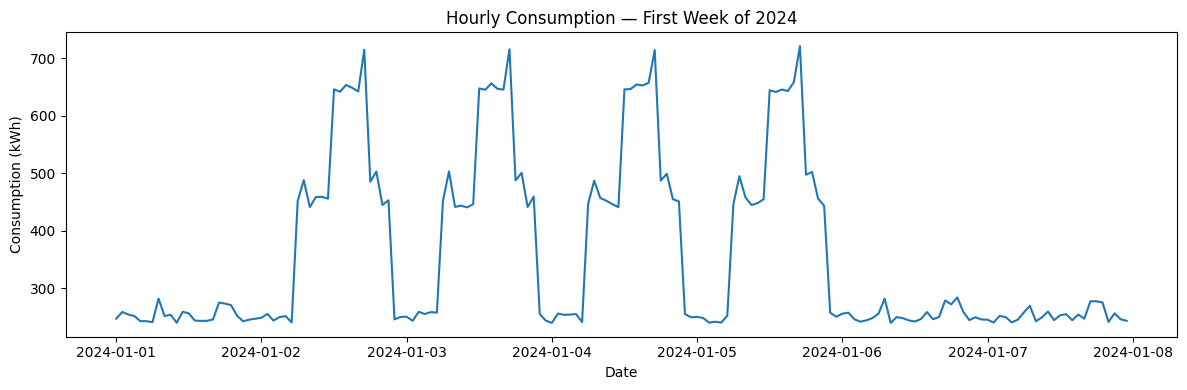

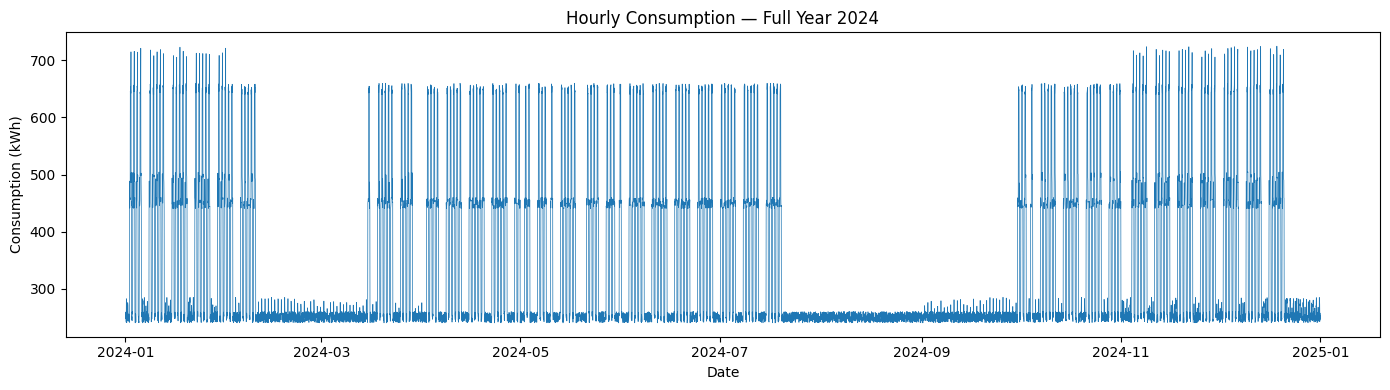

In [161]:
# Plot one week (first 7 days of January)
one_week = df[df["timestamp"] < "2024-01-08"]

plt.figure(figsize=(12, 4))
plt.plot(one_week["timestamp"], one_week["consumption_kwh"])
plt.title("Hourly Consumption — First Week of 2024")
plt.xlabel("Date")
plt.ylabel("Consumption (kWh)")
plt.tight_layout()
plt.show()

# Plot full year
plt.figure(figsize=(14, 4))
plt.plot(df["timestamp"], df["consumption_kwh"], linewidth=0.5)
plt.title("Hourly Consumption — Full Year 2024")
plt.xlabel("Date")
plt.ylabel("Consumption (kWh)")
plt.tight_layout()
plt.show()

### Monthly Electricity Consumption Analysis

This chart shows the total simulated electricity consumption for each month of 2024. Higher consumption is observed during active academic periods, while lower consumption occurs during semester breaks and holiday periods, particularly in August and September.

The results indicate that the dataset follows realistic seasonal and operational patterns expected for a university campus.


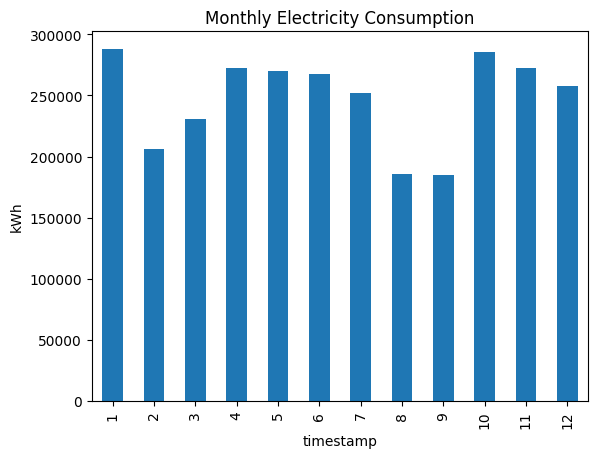

In [162]:
monthly_consumption = (
    df.groupby(df["timestamp"].dt.month)["consumption_kwh"]
    .sum()
)

monthly_consumption.plot(kind="bar")
plt.title("Monthly Electricity Consumption")
plt.ylabel("kWh")
plt.show()

### Average Electricity Consumption by Hour

This chart shows the average electricity consumption for each hour of the day across the entire year. The pattern reflects the university's daily operations, with higher consumption during active daytime hours and lower consumption during the night when campus activity is minimal.

The results confirm that the simulated dataset follows the expected hourly usage behavior and captures realistic variations in electricity demand throughout the day.

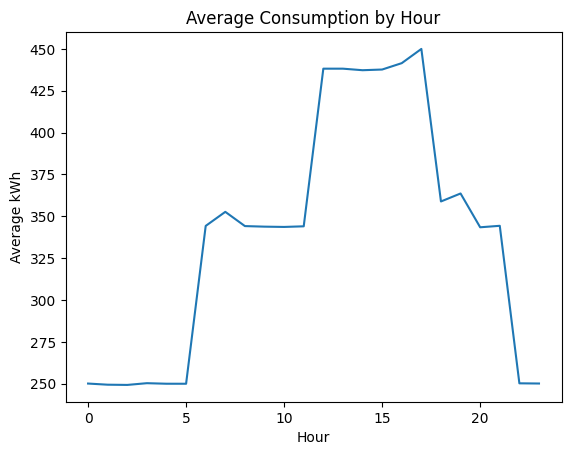

In [163]:
hourly_avg = df.groupby(df["timestamp"].dt.hour)["consumption_kwh"].mean()

hourly_avg.plot()
plt.title("Average Consumption by Hour")
plt.xlabel("Hour")
plt.ylabel("Average kWh")
plt.show()

### Average Electricity Consumption by Day of Week

This analysis shows the average electricity consumption for each day of the week throughout 2024. Weekday consumption remains consistently higher due to regular academic, administrative, and campus activities, while weekends show significantly lower consumption because of reduced occupancy and operational demand.

The results confirm that the dataset successfully captures the expected difference between weekdays and weekends, contributing to a more realistic representation of university electricity usage pattern

In [164]:
df.groupby("day_name")["consumption_kwh"].mean()

day_name
Friday       376.181651
Monday       366.857940
Saturday     251.516827
Sunday       251.545994
Thursday     369.038061
Tuesday      377.230346
Wednesday    376.253766
Name: consumption_kwh, dtype: float64

### Average Electricity Consumption: Semester vs Break

This chart compares the average electricity consumption during active academic semesters and semester break periods. As expected, consumption is noticeably higher during semesters due to increased campus occupancy, classroom usage, laboratory activities, and administrative operations.

The lower consumption during breaks reflects reduced campus activity, demonstrating that the dataset successfully incorporates the impact of the academic calendar on electricity demand.

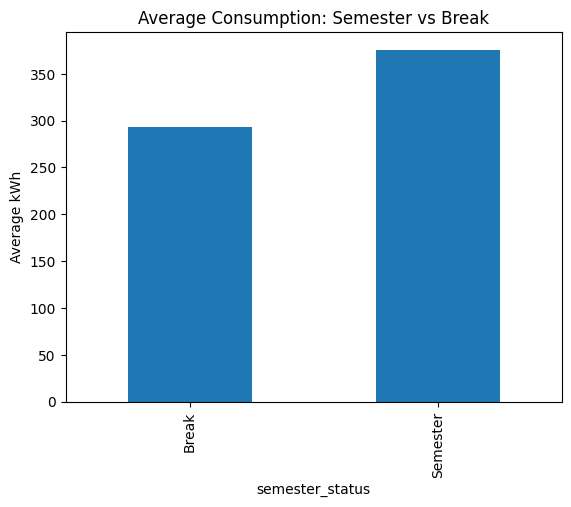

In [165]:
semester_avg = (
    df.groupby("semester_status")["consumption_kwh"]
    .mean()
)

semester_avg.plot(kind="bar")
plt.title("Average Consumption: Semester vs Break")
plt.ylabel("Average kWh")
plt.show()

### Data Quality and Validation Checks

To ensure the reliability of the generated dataset, several validation checks were performed. The results confirm that there are no missing values, no duplicate timestamps, and that the dataset contains all 8,784 hourly records expected for the leap year 2024.

These checks verify that the dataset is complete, consistent, and suitable for further analysis and sustainability reporting.

In [166]:
print("Missing values:")
print(df.isnull().sum())

print("Duplicate timestamps:")
print(df["timestamp"].duplicated().sum())

print("Total rows:")
print(len(df))

Missing values:
timestamp          0
hours              0
consumption_kwh    0
day_name           0
holiday            0
semester_status    0
dtype: int64
Duplicate timestamps:
0
Total rows:
8784


### Annual Electricity Consumption Summary

The generated dataset indicates a total annual electricity consumption of approximately 2.97 million kWh (2.97 GWh) for the year 2024. This value represents the combined electricity usage of the university campus, including academic buildings, administrative facilities, lighting, and other operational activities.

The annual total provides a useful baseline for sustainability reporting and demonstrates that the simulated dataset produces realistic and internally consistent consumption estimates.

In [167]:
annual_total = df["consumption_kwh"].sum()

print(f"Annual Consumption: {annual_total:,.2f} kWh")

Annual Consumption: 2,973,901.60 kWh


### Average Electricity Consumption: Holiday vs Non-Holiday

This chart compares the average electricity consumption during holidays and regular operating days. Electricity usage is noticeably lower on holidays due to reduced academic activities, lower campus occupancy, and decreased use of university facilities.

The results demonstrate that the holiday adjustments incorporated into the simulation successfully capture the expected reduction in electricity demand during non-operational periods.

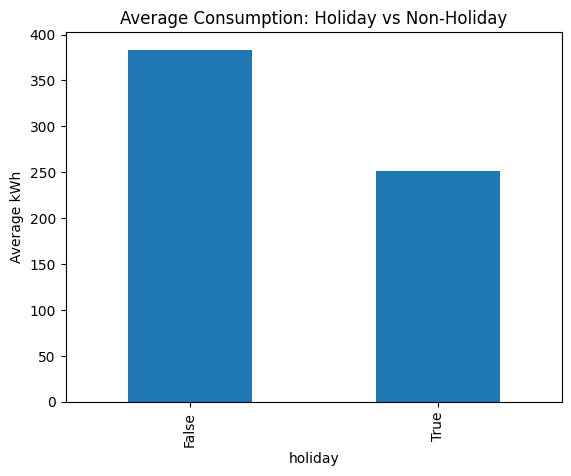

In [168]:
holiday_avg = (
    df.groupby("holiday")["consumption_kwh"]
    .mean()
)

holiday_avg.plot(kind="bar")
plt.title("Average Consumption: Holiday vs Non-Holiday")
plt.ylabel("Average kWh")
plt.show()

## Export to CSV

The final dataset is exported to `consumption.csv`. The file contains all 8,784 hourly rows with no missing values, covering every hour of 2024 from `2024-01-01 00:00:00` to `2024-12-31 23:00:00`.

In [169]:
df.to_csv("consumption.csv", index=False)